In [1]:
import os
import json
import numpy as np
import librosa
import pandas as pd
#import yaml
import matplotlib.pyplot as plt
import IPython
import soundfile as sf
from tqdm import tqdm 
from collections import OrderedDict
from sklearn.model_selection import train_test_split
import glob
import seaborn as sns
from tensorflow.keras import layers, models, Model
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint
import tensorflow as tf
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import multilabel_confusion_matrix
from tensorflow.keras.models import load_model

In [2]:
# First, we define the mapping we already agreed on
# Mapping from original instruments to grouped categories
instrument_mapping = {
    # Large individual classes
    'electric_bass': 'electric_bass',
    'drum_set': 'drum_set',
    'piano': 'piano',
    'tack_piano': 'piano',
    'synthesizer': 'synthesizer',
    'electric_piano': 'synthesizer',
    'clean_electric_guitar': 'clean_electric_guitar',
    'distorted_electric_guitar': 'distorted_electric_guitar',
    'acoustic_guitar': 'acoustic_guitar',
    'violin': 'violin',
    'female_singer': 'female_singer',
    'vocalists': 'vocalists',
    
    # Male vocals
    'male_singer': 'male_vocals',
    'male_speaker': 'male_vocals',
    'male_rapper': 'male_vocals',
    
    # Other bowed strings
    'viola': 'other_bowed_strings',
    'cello': 'other_bowed_strings',
    'double_bass': 'other_bowed_strings',
    'violin_section': 'other_bowed_strings',
    'viola_section': 'other_bowed_strings',
    'cello_section': 'other_bowed_strings',
    'string_section': 'other_bowed_strings',
    'erhu': 'other_bowed_strings',
    
    # Woodwinds
    'flute': 'woodwinds',
    'clarinet': 'woodwinds',
    'oboe': 'woodwinds',
    'bassoon': 'woodwinds',
    'tenor_saxophone': 'woodwinds',
    'soprano_saxophone': 'woodwinds',
    'alto_saxophone': 'woodwinds',
    'baritone_saxophone': 'woodwinds',
    'bass_clarinet': 'woodwinds',
    'piccolo': 'woodwinds',
    'flute_section': 'woodwinds',
    'clarinet_section': 'woodwinds',
    
    # Brass
    'trumpet': 'brass',
    'trombone': 'brass',
    'french_horn': 'brass',
    'french_horn_section': 'brass',
    'brass_section': 'brass',
    'tuba': 'brass',
    'horn_section': 'brass',
    'trumpet_section': 'brass',
    
    # Other percussion
    'auxiliary_percussion': 'other_percussion',
    'tambourine': 'other_percussion',
    'cymbals': 'other_percussion',
    'timpani': 'other_percussion',
    'tabla': 'other_percussion',
    'shaker': 'other_percussion',
    'snare_drum': 'other_percussion',
    'bass_drum': 'other_percussion',
    'kick_drum': 'other_percussion',
    'bongo': 'other_percussion',
    'darbuka': 'other_percussion',
    'doumbek': 'other_percussion',
    'gong': 'other_percussion',
    'toms': 'other_percussion',
    'drum_machine': 'other_percussion',
    'claps': 'other_percussion',
    'chimes': 'other_percussion',
    
    # Other plucked strings
    'mandolin': 'other_plucked_strings',
    'banjo': 'other_plucked_strings',
    'guzheng': 'other_plucked_strings',
    'oud': 'other_plucked_strings',
    'harp': 'other_plucked_strings',
    'lap_steel_guitar': 'other_plucked_strings',
    'yangqin': 'other_plucked_strings',
    'zhongruan': 'other_plucked_strings',
    'glockenspiel': 'other_plucked_strings',
    'vibraphone': 'other_plucked_strings',
    
    # Reed instruments
    'accordion': 'reed_instruments',
    'harmonica': 'reed_instruments',
    'melodica': 'reed_instruments',
    
    # Effects and processed sounds
    'fx_slash_processed_sound': 'fx_and_processed',
    'scratches': 'fx_and_processed'
}

# List of instruments to completely discard
instruments_to_discard = [
    'sampler',
    'main_system',
    'trombone_section',
]

# Final categories
instrument_categories = [
    'electric_bass',
    'drum_set',
    'piano',
    'synthesizer',
    'clean_electric_guitar',
    'distorted_electric_guitar',
    'acoustic_guitar',
    'violin',
    'female_singer',
    'vocalists',
    'male_vocals',
    'other_bowed_strings',
    'woodwinds',
    'brass',
    'other_percussion',
    'other_plucked_strings',
    'reed_instruments',
    'fx_and_processed'
]

# Mapping from categories to indices
category_to_idx = {category: idx for idx, category in enumerate(instrument_categories)}

In [3]:
def plot_instrument_histogram(instrument_counts, top_n=20, min_count=None):
    """
    Creates a horizontal histogram with the frequencies of the instruments.
    
    Args:
        instrument_counts: Dictionary with instrument as key and frequency as value
        top_n: Show only the top N most frequent instruments (default 20)
        min_count: Minimum appearance threshold to include an instrument
    """
    # Sort instruments by frequency (highest to lowest)
    sorted_instruments = sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True)
    
    # Filter according to parameters
    filtered_instruments = []
    for instrument, count in sorted_instruments:
        if min_count is not None and count < min_count:
            continue
        filtered_instruments.append((instrument, count))
        if len(filtered_instruments) >= top_n:
            break
    
    # Separate names and counts for the plot
    names = [item[0] for item in filtered_instruments]
    counts = [item[1] for item in filtered_instruments]
    
    # Create figure with size adapted to the number of instruments
    plt.figure(figsize=(16, max(8, len(names) * 0.3)))
    
    # Create horizontal bars
    plt.barh(names, counts, color='skyblue')
    
    # Add labels and title
    plt.xlabel('Number of appearances')
    plt.title('Instrument frequency in MedleyDB')
    
    # Adjust margins
    plt.tight_layout()
    
    # Add the numeric value at the end of each bar
    for i, count in enumerate(counts):
        plt.text(count + 0.5, i, str(count), va='center')
    
    # Show the plot
    plt.show()

# Load data

In [4]:
X_stem_cqt = np.load(os.path.join('extracted_segments_features', 'processed_features_cqt.npy'))  # or cqt
X_stem_mel = np.load(os.path.join('extracted_segments_features', 'processed_features_mel.npy'))  # or cqt
y_stem = np.load(os.path.join('extracted_segments_features', 'processed_labels.npy'))
X_mix_mel = np.load("extracted_mix_features/all_mels.npy")
X_mix_cqt = np.load("extracted_mix_features/all_cqts.npy")
y_mix = np.load("extracted_mix_features/all_labels.npy")

# Distributions


Class distribution in the filtered dataset:
  other_percussion: 9085 samples (13.2%)
  electric_bass: 6781 samples (9.8%)
  drum_set: 6300 samples (9.1%)
  piano: 5604 samples (8.1%)
  other_bowed_strings: 4946 samples (7.2%)
  clean_electric_guitar: 4790 samples (7.0%)
  synthesizer: 4711 samples (6.8%)
  other_plucked_strings: 3635 samples (5.3%)
  fx_and_processed: 3452 samples (5.0%)
  male_vocals: 3180 samples (4.6%)
  violin: 3010 samples (4.4%)
  distorted_electric_guitar: 2475 samples (3.6%)
  acoustic_guitar: 2452 samples (3.6%)
  female_singer: 2190 samples (3.2%)
  woodwinds: 1860 samples (2.7%)
  vocalists: 1565 samples (2.3%)
  reed_instruments: 1460 samples (2.1%)
  brass: 1383 samples (2.0%)


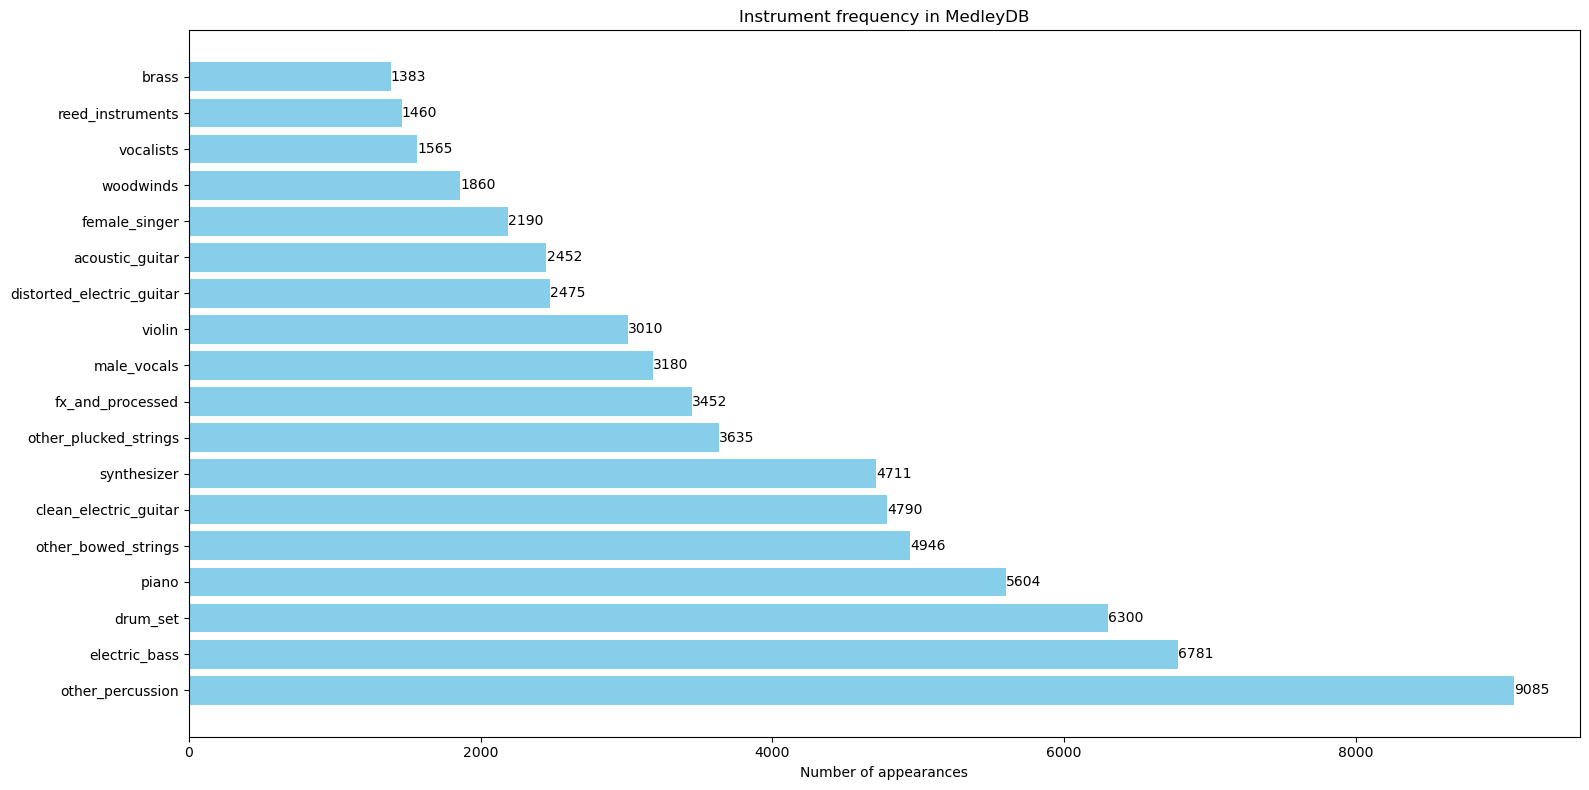


Dataset dimensions:
  Filtered data: (68879, 96, 130)
  Total number of samples: 68879
  Number of categories: 18


In [5]:
idx_to_category = {v: k for k, v in category_to_idx.items()}
ordered_labels = [idx_to_category[i] for i in range(len(idx_to_category))]

# Compute distribution of current class labels
unique_classes, class_counts = np.unique(y_stem, return_counts=True)

# Create a dictionary: {category_name: count}
category_counts = {}
for idx, count in zip(unique_classes, class_counts):
    category_name = ordered_labels[idx]
    category_counts[category_name] = count

# Show the distribution
print("\nClass distribution in the filtered dataset:")
for category, count in sorted(category_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"  {category}: {count} samples ({count / len(y_stem) * 100:.1f}%)")

# Plot histogram
plot_instrument_histogram(category_counts, top_n=len(ordered_labels))

# Dataset summary
print(f"\nDataset dimensions:")
print(f"  Filtered data: {X_stem_mel.shape}")
print(f"  Total number of samples: {len(y_stem)}")
print(f"  Number of categories: {len(ordered_labels)}")


Distribución de clases en el dataset filtrado:
  electric_bass: 4100 muestras (44.8%)
  drum_set: 3884 muestras (42.4%)
  piano: 3395 muestras (37.1%)
  other_percussion: 2597 muestras (28.4%)
  clean_electric_guitar: 2402 muestras (26.2%)
  other_plucked_strings: 1767 muestras (19.3%)
  other_bowed_strings: 1760 muestras (19.2%)
  male_vocals: 1733 muestras (18.9%)
  synthesizer: 1558 muestras (17.0%)
  acoustic_guitar: 1526 muestras (16.7%)
  female_singer: 1330 muestras (14.5%)
  fx_and_processed: 1108 muestras (12.1%)
  distorted_electric_guitar: 1097 muestras (12.0%)
  vocalists: 851 muestras (9.3%)
  violin: 785 muestras (8.6%)
  woodwinds: 750 muestras (8.2%)
  reed_instruments: 750 muestras (8.2%)
  brass: 653 muestras (7.1%)


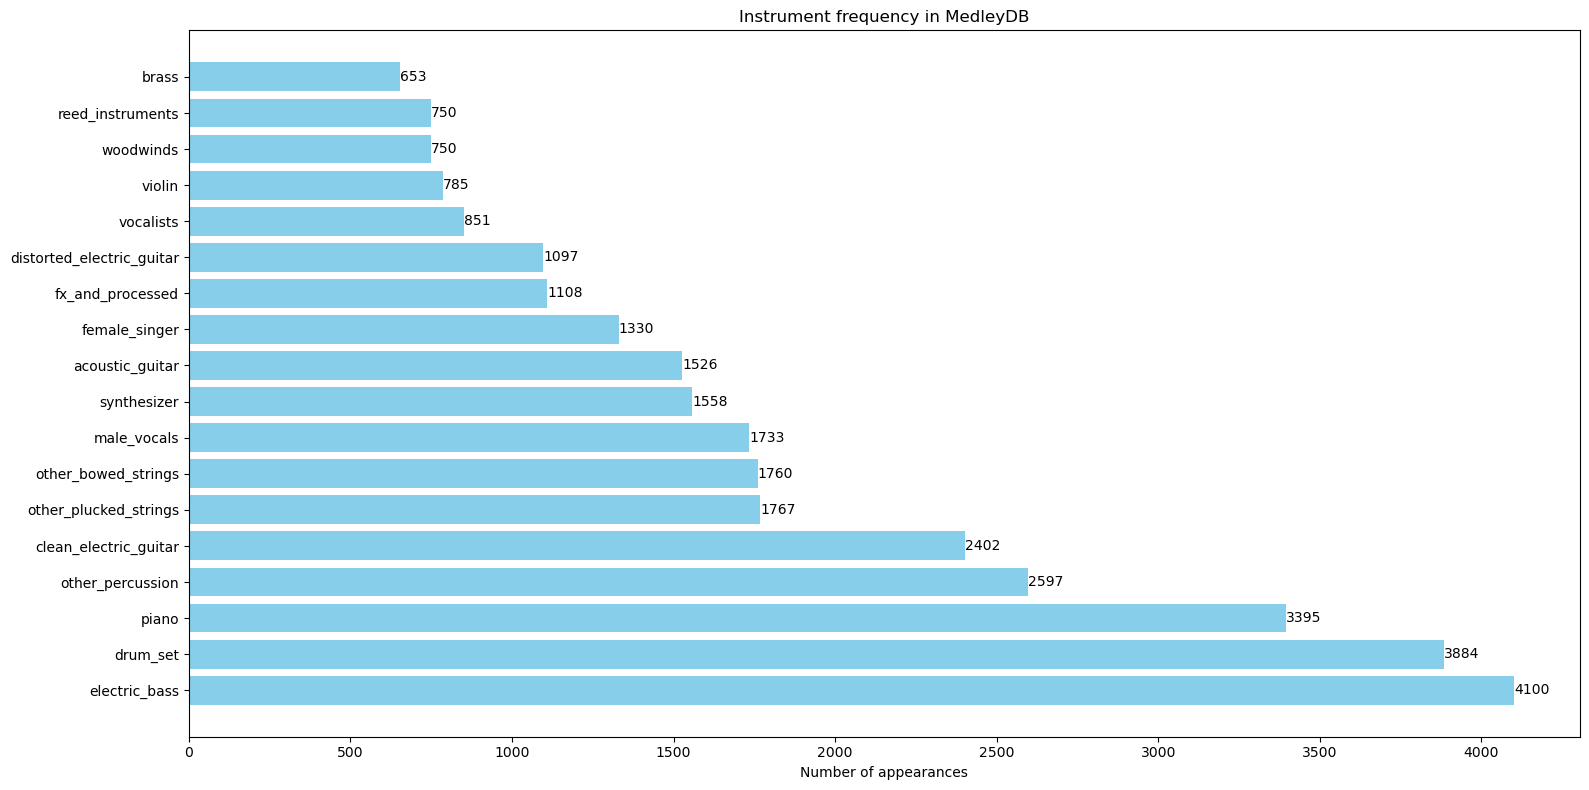


Dimensiones del dataset:
  X: (9154, 96, 130)
  y filtrado (multi-hot): (9154, 18)
  Total de muestras: 9154
  Número de categorías actuales: 18


In [6]:
# Sumar cuántas veces aparece cada clase (suma por columnas)
class_counts = np.sum(y_mix, axis=0)

# Crear diccionario {nombre_categoria: cantidad}
category_counts = {label: int(count) for label, count in zip(ordered_labels, class_counts)}

# Mostrar la distribución
print("\nDistribución de clases en el dataset filtrado:")
for category, count in sorted(category_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"  {category}: {count} muestras ({count / len(y_mix) * 100:.1f}%)")

# Graficar histograma
plot_instrument_histogram(category_counts, top_n=len(ordered_labels))

# Resumen general
print(f"\nDimensiones del dataset:")
print(f"  X: {X_mix_cqt.shape}")
print(f"  y filtrado (multi-hot): {y_mix.shape}")
print(f"  Total de muestras: {len(y_mix)}")
print(f"  Número de categorías actuales: {len(ordered_labels)}")

# Normalize


In [7]:
mean_cqt = np.mean(X_mix_cqt)
std_cqt = np.std(X_mix_cqt)

mean_mel = np.mean(X_mix_mel)
std_mel = np.std(X_mix_mel)

X_stem_cqt = (X_stem_cqt - mean_cqt) / (std_cqt + 1e-6)
X_stem_mel = (X_stem_mel - mean_mel) / (std_mel + 1e-6)

X_mix_cqt = (X_mix_cqt - mean_cqt) / (std_cqt + 1e-6)
X_mix_mel = (X_mix_mel - mean_mel) / (std_mel + 1e-6)

# Splitting data

In [8]:
'''
# Split into train, validation, and test sets for stem cqt
X_temp, X_test_stem_cqt, y_temp, y_test_stem = train_test_split(
    X_stem_cqt, y_stem, test_size=0.1, random_state=42
)
X_train_stem_cqt, X_val_stem_cqt, y_train_stem, y_val_stem = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42
)

# Split into train, validation, and test sets for mix cqt
X_temp, X_test_mix_cqt, y_temp, y_test_mix = train_test_split(
    X_mix_cqt, y_mix, test_size=0.1, random_state=42
)
X_train_mix_cqt, X_val_mix_cqt, y_train_mix, y_val_mix = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42
)
'''

# Split into train, validation, and test sets for stem mel
X_temp, X_test_stem_mel, y_temp, y_test_stem = train_test_split(
    X_stem_mel, y_stem, test_size=0.1, random_state=42
)
X_train_stem_mel, X_val_stem_mel, y_train_stem, y_val_stem = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42
)

# Split into train, validation, and test sets for mix mel
X_temp, X_test_mix_mel, y_temp, y_test_mix = train_test_split(
    X_mix_cqt, y_mix, test_size=0.1, random_state=42
)
X_train_mix_mel, X_val_mix_mel, y_train_mix, y_val_mix = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42
)

# Model 1 - Stems

In [9]:
input_shape = (96, 130, 1)
num_classes = len(ordered_labels)

model_phase1 = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=(96, 130, 1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='softmax')  # softmax for stems (single label)
])

model_phase1.compile(optimizer='adam',
                     loss='sparse_categorical_crossentropy',
                     metrics=['accuracy'])
model_phase1.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 96, 130, 16)       160       
                                                                 
 batch_normalization (BatchN  (None, 96, 130, 16)      64        
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 48, 65, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_1 (Batc  (None, 48, 65, 32)       128       
 hNormalization)                                                 
                                                        

In [10]:
# Callbacks for phase 1
callbacks_phase1 = [
    CSVLogger('training_model_hybrid_stems.log', append=False),
    EarlyStopping(monitor='val_loss', patience=25),
    ModelCheckpoint('best_model_hybrid_stems.h5', monitor='val_accuracy', save_best_only=True, verbose=1)
]

# Train on stems
model_phase1.fit(
    X_train_stem_mel, y_train_stem,
    validation_data=(X_val_stem_mel, y_val_stem),
    epochs=200,
    batch_size=32,
    callbacks=callbacks_phase1
)

Epoch 1/200
1615/1615 [==============================] - ETA: 0s - loss: 1.6178 - accuracy: 0.4796
Epoch 1: val_accuracy improved from -inf to 0.62689, saving model to best_model_hybrid_stems.h5
1615/1615 [==============================] - 22s 10ms/step - loss: 1.6178 - accuracy: 0.4796 - val_loss: 1.1270 - val_accuracy: 0.6269
Epoch 2/200
1611/1615 [============================>.] - ETA: 0s - loss: 1.1025 - accuracy: 0.6354
Epoch 2: val_accuracy improved from 0.62689 to 0.65002, saving model to best_model_hybrid_stems.h5
1615/1615 [==============================] - 16s 10ms/step - loss: 1.1021 - accuracy: 0.6355 - val_loss: 1.0190 - val_accuracy: 0.6500
Epoch 3/200
1612/1615 [============================>.] - ETA: 0s - loss: 0.9480 - accuracy: 0.6852
Epoch 3: val_accuracy did not improve from 0.65002
1615/1615 [==============================] - 16s 10ms/step - loss: 0.9479 - accuracy: 0.6852 - val_loss: 2.1599 - val_accuracy: 0.4370
Epoch 4/200
1614/1615 [============================>

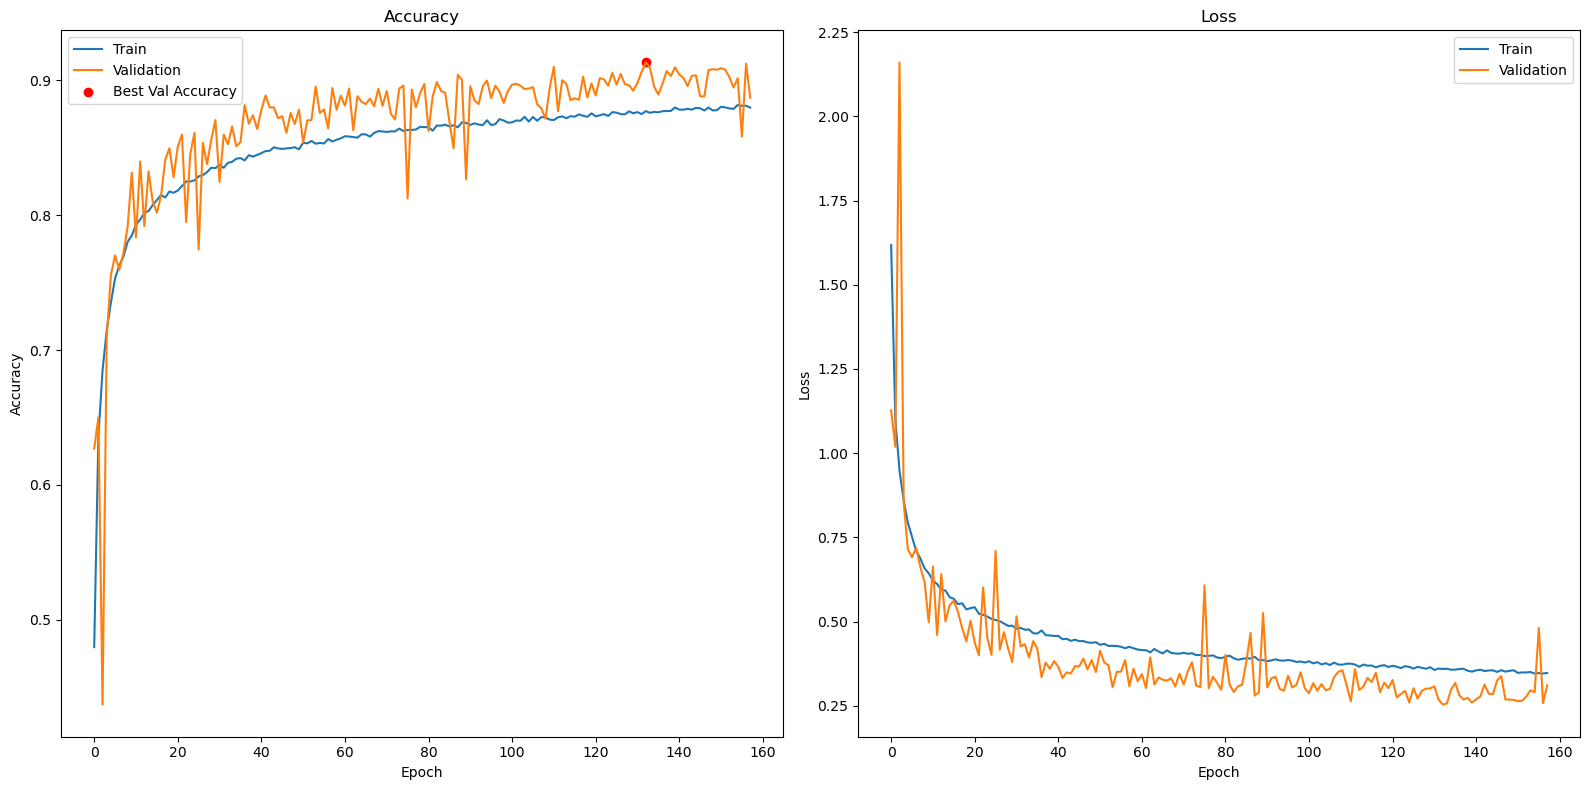

In [10]:
# History plot
log_df = pd.read_csv('training_model_hybrid_stems.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

216/216 [==============================] - 0s 2ms/step


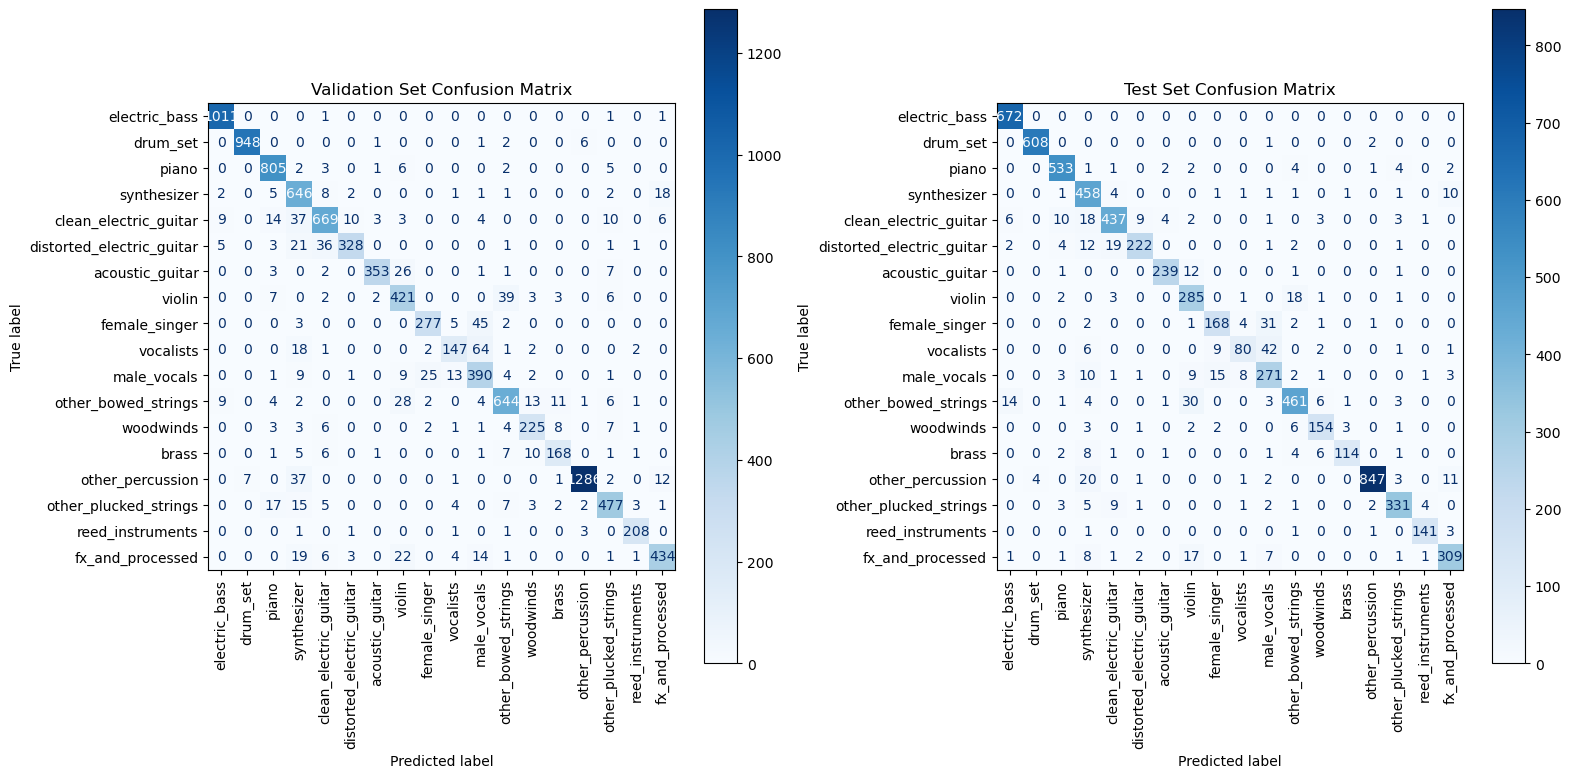

In [11]:
model_phase1.load_weights('best_model_hybrid_stems.h5')

# Predict class probabilities
y_val_pred_prob = model_phase1.predict(X_val_stem_mel)
y_test_pred_prob = model_phase1.predict(X_test_stem_mel)

# Get predicted class indices
y_val_pred = y_val_pred_prob.argmax(axis=1)
y_test_pred = y_test_pred_prob.argmax(axis=1)

# Compute confusion matrices
val_cm = confusion_matrix(y_val_stem, y_val_pred)
test_cm = confusion_matrix(y_test_stem, y_test_pred)

# Plot confusion matrices
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Validation Set Confusion Matrix")
plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [12]:
# For classification report
print(classification_report(y_val_stem, y_val_pred, target_names=ordered_labels))
print(classification_report(y_test_stem, y_test_pred, target_names=ordered_labels))

                           precision    recall  f1-score   support

            electric_bass       0.98      1.00      0.99      1014
                 drum_set       0.99      0.99      0.99       958
                    piano       0.93      0.98      0.95       824
              synthesizer       0.79      0.94      0.86       686
    clean_electric_guitar       0.90      0.87      0.89       765
distorted_electric_guitar       0.95      0.83      0.89       396
          acoustic_guitar       0.98      0.90      0.94       393
                   violin       0.82      0.87      0.84       483
            female_singer       0.90      0.83      0.87       332
                vocalists       0.83      0.62      0.71       237
              male_vocals       0.74      0.86      0.80       455
      other_bowed_strings       0.90      0.89      0.89       725
                woodwinds       0.87      0.86      0.87       261
                    brass       0.87      0.84      0.85     

# Model 2 - Mix

In [13]:
model_best_stems = load_model('best_model_hybrid_stems.h5')

# Extraer capas y reconstruir funcionalmente
inputs = layers.Input(shape=(96, 130, 1))
x = model_best_stems.layers[0](inputs)
for layer in model_best_stems.layers[1:-1]:  # Excluye la última:  Dense(softmax)
    x = layer(x)

# x = layers.Dense(64, activation='relu')(x)
#x = layers.Dropout(0.5)(x)
outputs = layers.Dense(num_classes, activation='sigmoid', name='output')(x)

model_phase2 = Model(inputs=inputs, outputs=outputs)


# === FREEZE CONVOLUTIONAL LAYERS ===

# Option: freeze first N Conv2D layers
N = 0  # Change this value (0–3) to freeze desired number of conv layers
conv_layers_frozen = 0
for layer in model_phase2.layers:
    if isinstance(layer, layers.Conv2D):
        if conv_layers_frozen < N:
            layer.trainable = False
            conv_layers_frozen += 1

# Compile for multilabel
model_phase2.compile(optimizer='adam',
                     loss='binary_crossentropy',
                     metrics=['binary_accuracy'])
model_phase2.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 96, 130, 1)]      0         
                                                                 
 conv2d (Conv2D)             (None, 96, 130, 16)       160       
                                                                 
 batch_normalization (BatchN  (None, 96, 130, 16)      64        
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 48, 65, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_1 (Batc  (None, 48, 65, 32)       128   

In [13]:
# Callbacks for phase 2
callbacks_phase2 = [
    CSVLogger('training_model_hybrid_mix.log', append=False),
    EarlyStopping(monitor='val_loss', patience=50),
    ModelCheckpoint('best_model_hybrid_mix.h5', monitor='val_binary_accuracy', save_best_only=True, verbose=1)
]

# Train on mixes
history = model_phase2.fit(
    X_train_mix_mel, y_train_mix,
    validation_data=(X_val_mix_mel, y_val_mix),
    epochs=300,
    batch_size=32,
    callbacks=callbacks_phase2
)

Epoch 1/300
215/215 [==============================] - ETA: 0s - loss: 0.4659 - binary_accuracy: 0.7944
Epoch 1: val_binary_accuracy improved from -inf to 0.83831, saving model to best_model_hybrid_mix.h5
215/215 [==============================] - 3s 11ms/step - loss: 0.4659 - binary_accuracy: 0.7944 - val_loss: 0.3898 - val_binary_accuracy: 0.8383
Epoch 2/300
213/215 [============================>.] - ETA: 0s - loss: 0.3751 - binary_accuracy: 0.8461
Epoch 2: val_binary_accuracy improved from 0.83831 to 0.85429, saving model to best_model_hybrid_mix.h5
215/215 [==============================] - 2s 10ms/step - loss: 0.3749 - binary_accuracy: 0.8463 - val_loss: 0.3462 - val_binary_accuracy: 0.8543
Epoch 3/300
215/215 [==============================] - ETA: 0s - loss: 0.3466 - binary_accuracy: 0.8551
Epoch 3: val_binary_accuracy improved from 0.85429 to 0.86000, saving model to best_model_hybrid_mix.h5
215/215 [==============================] - 2s 10ms/step - loss: 0.3466 - binary_accurac

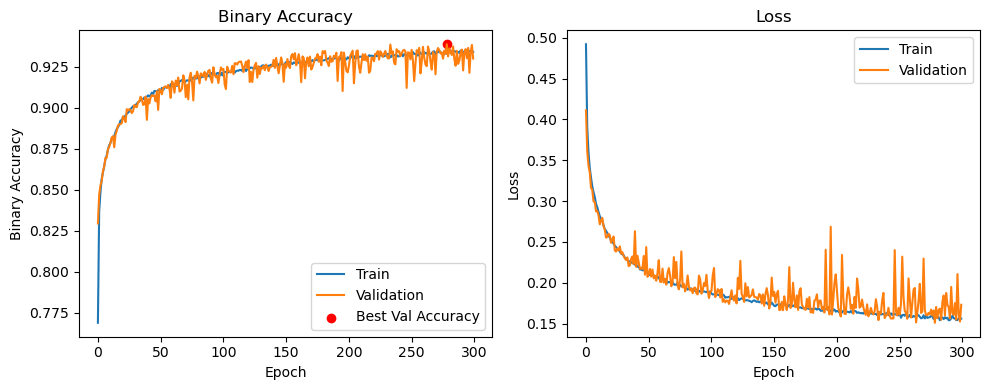

In [14]:
# History plot
log_df = pd.read_csv('training_model_hybrid_mix.log')
best_val_acc = max(log_df['val_binary_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_binary_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['binary_accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_binary_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Binary Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Binary Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

29/29 [==============================] - 0s 2ms/step


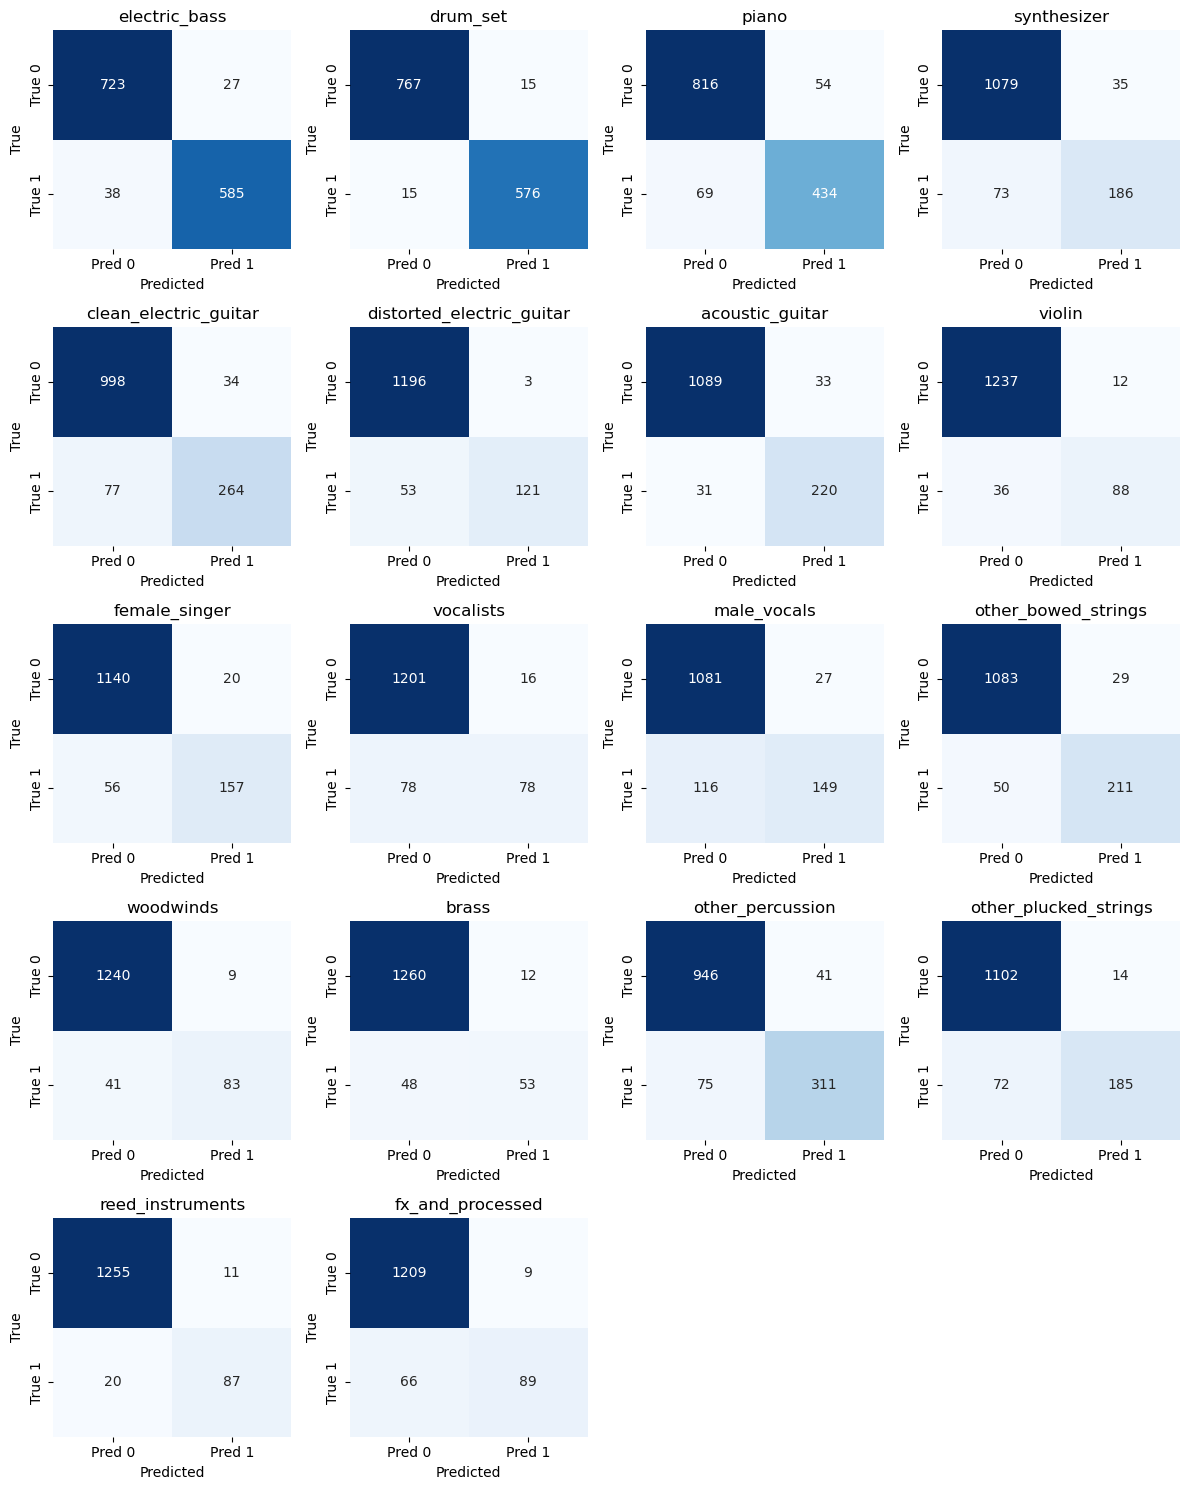

In [16]:
# Confusion matrix for validation and test sets
model_phase2.load_weights('best_model_hybrid_mix.h5')

# Predict probabilities
y_val_pred_prob = model_phase2.predict(X_val_mix_mel)
y_test_pred_prob = model_phase2.predict(X_test_mix_mel)

# Binarize predictions (threshold = 0.5)
y_val_pred = (y_val_pred_prob >= 0.5).astype(int)
y_test_pred = (y_test_pred_prob >= 0.5).astype(int)

# Compute multilabel confusion matrices
val_cm = multilabel_confusion_matrix(y_val_mix, y_val_pred)
test_cm = multilabel_confusion_matrix(y_test_mix, y_test_pred)

# Plot confusion matrices for each category
num_classes = len(instrument_categories)
cols = 4  # Number of columns in the plot grid
rows = (num_classes + cols - 1) // cols

plt.figure(figsize=(3*cols, 3*rows))
for i, category in enumerate(instrument_categories):
    plt.subplot(rows, cols, i+1)
    sns.heatmap(val_cm[i], annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
    plt.title(category)
    plt.xlabel('Predicted')
    plt.ylabel('True')
plt.tight_layout()
plt.show()

In [17]:
# Classification report for validation and test sets
print(classification_report(y_val_mix, y_val_pred))
print(classification_report(y_test_mix, y_test_pred))

              precision    recall  f1-score   support

           0       0.96      0.94      0.95       623
           1       0.97      0.97      0.97       591
           2       0.89      0.86      0.88       503
           3       0.84      0.72      0.78       259
           4       0.89      0.77      0.83       341
           5       0.98      0.70      0.81       174
           6       0.87      0.88      0.87       251
           7       0.88      0.71      0.79       124
           8       0.89      0.74      0.81       213
           9       0.83      0.50      0.62       156
          10       0.85      0.56      0.68       265
          11       0.88      0.81      0.84       261
          12       0.90      0.67      0.77       124
          13       0.82      0.52      0.64       101
          14       0.88      0.81      0.84       386
          15       0.93      0.72      0.81       257
          16       0.89      0.81      0.85       107
          17       0.91    

c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# Model 3

In [18]:
model_best_stems = load_model('best_model_hybrid_stems.h5')

# Extraer capas y reconstruir funcionalmente
inputs = layers.Input(shape=(96, 130, 1))
x = model_best_stems.layers[0](inputs)
for layer in model_best_stems.layers[1:-1]:  # Excluye la última:  Dense(softmax)
    x = layer(x)

# x = layers.Dense(64, activation='relu')(x)
#x = layers.Dropout(0.5)(x)
outputs = layers.Dense(num_classes, activation='sigmoid', name='output')(x)

model_phase3 = Model(inputs=inputs, outputs=outputs)


# === FREEZE CONVOLUTIONAL LAYERS ===

# Option: freeze first N Conv2D layers
N = 0  # Change this value (0–3) to freeze desired number of conv layers
conv_layers_frozen = 0
for layer in model_phase3.layers:
    if isinstance(layer, layers.Conv2D):
        if conv_layers_frozen < N:
            layer.trainable = False
            conv_layers_frozen += 1

# Compile for multilabel
model_phase3.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.Precision(name='precision'),
        'binary_accuracy'
    ]
)
model_phase3.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 96, 130, 1)]      0         
                                                                 
 conv2d (Conv2D)             (None, 96, 130, 16)       160       
                                                                 
 batch_normalization (BatchN  (None, 96, 130, 16)      64        
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 48, 65, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_1 (Batc  (None, 48, 65, 32)       128 

In [19]:
# Callbacks for phase 3
callbacks_phase3 = [
    CSVLogger('training_model_hybrid_mix_2.log', append=False),
    EarlyStopping(monitor='val_loss', patience=50),
    ModelCheckpoint('best_model_hybrid_mix_2.h5', monitor='binary_accuracy', save_best_only=True, verbose=1)
]

# Train on mixes
history = model_phase3.fit(
    X_train_mix_mel, y_train_mix,
    validation_data=(X_val_mix_mel, y_val_mix),
    epochs=300,
    batch_size=32,
    callbacks=callbacks_phase3
)

Epoch 1/300
215/215 [==============================] - ETA: 0s - loss: 0.4857 - recall: 0.2550 - precision: 0.3866 - binary_accuracy: 0.7769
Epoch 1: binary_accuracy improved from -inf to 0.77686, saving model to best_model_hybrid_mix_2.h5
215/215 [==============================] - 4s 11ms/step - loss: 0.4857 - recall: 0.2550 - precision: 0.3866 - binary_accuracy: 0.7769 - val_loss: 0.4125 - val_recall: 0.2909 - val_precision: 0.6634 - val_binary_accuracy: 0.8305
Epoch 2/300
209/215 [============================>.] - ETA: 0s - loss: 0.3880 - recall: 0.3358 - precision: 0.6742 - binary_accuracy: 0.8394
Epoch 2: binary_accuracy improved from 0.77686 to 0.83982, saving model to best_model_hybrid_mix_2.h5
215/215 [==============================] - 2s 10ms/step - loss: 0.3871 - recall: 0.3367 - precision: 0.6752 - binary_accuracy: 0.8398 - val_loss: 0.3682 - val_recall: 0.3363 - val_precision: 0.7491 - val_binary_accuracy: 0.8464
Epoch 3/300
214/215 [============================>.] - ETA: 0

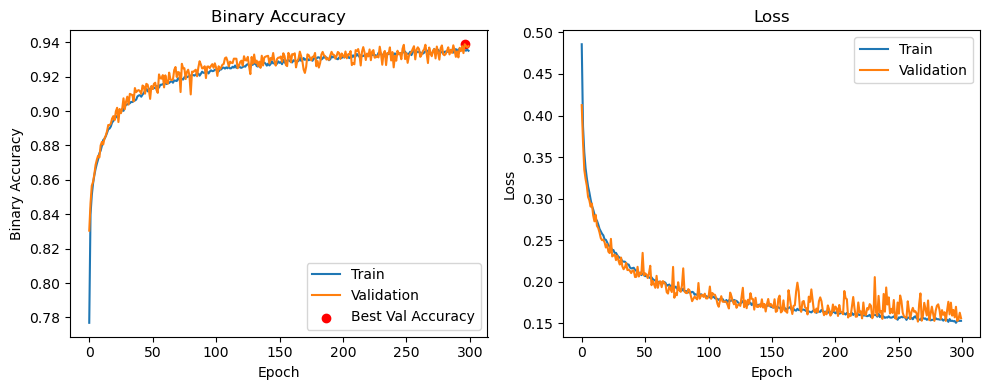

In [20]:
# History plot
log_df = pd.read_csv('training_model_hybrid_mix_2.log')
best_val_acc = max(log_df['val_binary_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_binary_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['binary_accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_binary_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Binary Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Binary Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

29/29 [==============================] - 0s 2ms/step


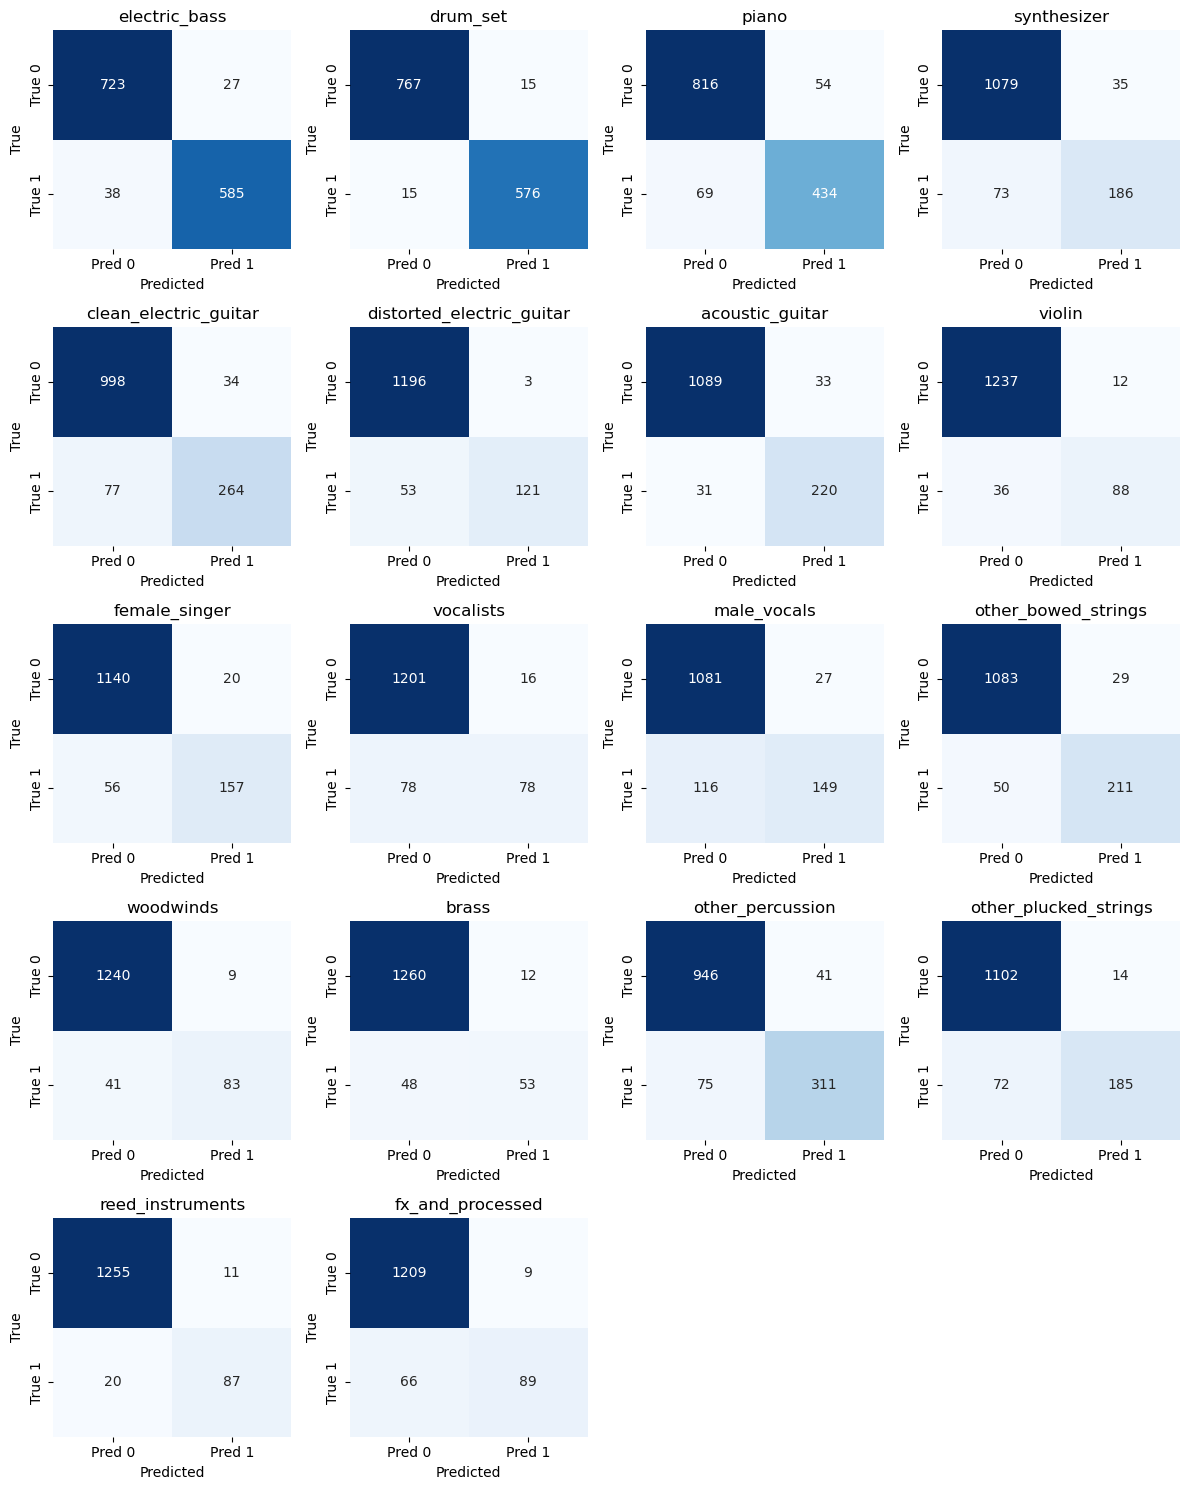

In [21]:
# Predict probabilities
y_val_pred_prob = model_phase2.predict(X_val_mix_mel)
y_test_pred_prob = model_phase2.predict(X_test_mix_mel)

# Binarize predictions (threshold = 0.5)
y_val_pred = (y_val_pred_prob >= 0.5).astype(int)
y_test_pred = (y_test_pred_prob >= 0.5).astype(int)

# Compute multilabel confusion matrices
val_cm = multilabel_confusion_matrix(y_val_mix, y_val_pred)
test_cm = multilabel_confusion_matrix(y_test_mix, y_test_pred)

num_classes = len(instrument_categories)
cols = 4  # Number of columns in the plot grid
rows = (num_classes + cols - 1) // cols

plt.figure(figsize=(3*cols, 3*rows))
for i, category in enumerate(instrument_categories):
    plt.subplot(rows, cols, i+1)
    sns.heatmap(val_cm[i], annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
    plt.title(category)
    plt.xlabel('Predicted')
    plt.ylabel('True')
plt.tight_layout()
plt.show()

In [22]:
# Classification report for validation and test sets
print(classification_report(y_val_mix, y_val_pred))
print(classification_report(y_test_mix, y_test_pred))

              precision    recall  f1-score   support

           0       0.96      0.94      0.95       623
           1       0.97      0.97      0.97       591
           2       0.89      0.86      0.88       503
           3       0.84      0.72      0.78       259
           4       0.89      0.77      0.83       341
           5       0.98      0.70      0.81       174
           6       0.87      0.88      0.87       251
           7       0.88      0.71      0.79       124
           8       0.89      0.74      0.81       213
           9       0.83      0.50      0.62       156
          10       0.85      0.56      0.68       265
          11       0.88      0.81      0.84       261
          12       0.90      0.67      0.77       124
          13       0.82      0.52      0.64       101
          14       0.88      0.81      0.84       386
          15       0.93      0.72      0.81       257
          16       0.89      0.81      0.85       107
          17       0.91    

c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
